In [2]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
warnings.filterwarnings("ignore")

In [7]:
GROUP = "C1"
DTYPE="LBP"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C1_10,27,"[DATA/TRAINING/C1/C1_10/IMG_6497.HEIC, DATA/TR..."
1,C1_11,26,"[DATA/TRAINING/C1/C1_11/IMG_6665.HEIC, DATA/TR..."
2,C1_12,27,"[DATA/TRAINING/C1/C1_12/IMG_6797.HEIC, DATA/TR..."
3,C1_13,27,"[DATA/TRAINING/C1/C1_13/IMG_6929.HEIC, DATA/TR..."
4,C1_14,26,"[DATA/TRAINING/C1/C1_14/IMG_7188.HEIC, DATA/TR..."
5,C1_15,28,"[DATA/TRAINING/C1/C1_15/IMG_7316.HEIC, DATA/TR..."
6,C1_16,27,"[DATA/TRAINING/C1/C1_16/IMG_7446.HEIC, DATA/TR..."


In [8]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [9]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [10]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

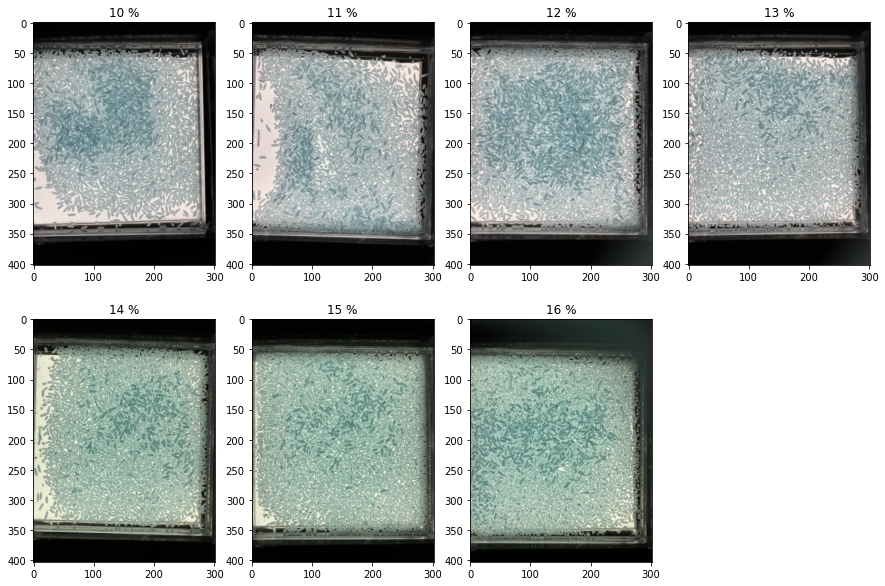

In [11]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16 %")

In [12]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [201]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [202]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.076852,0.056759,0.026389,0.017315,0.012407,0.013981,0.014259,0.022778,0.054074,0.055648,...,0.117593,0.386111,3,16,2,120,90,3,IMG_6497.HEIC,10
1,0.075278,0.057778,0.025556,0.019167,0.014259,0.012407,0.014259,0.028241,0.062778,0.061852,...,0.117037,0.370093,3,16,2,120,90,3,IMG_6498.HEIC,10
2,0.075463,0.056759,0.028056,0.018519,0.010926,0.012870,0.012593,0.024352,0.060000,0.062407,...,0.116944,0.372685,3,16,2,120,90,3,IMG_6499.HEIC,10
3,0.076667,0.056389,0.022130,0.018796,0.010370,0.012222,0.013333,0.032222,0.062222,0.066667,...,0.106759,0.368704,3,16,2,120,90,3,IMG_6500.HEIC,10
4,0.078889,0.056481,0.027315,0.015741,0.010185,0.010556,0.012593,0.026574,0.059722,0.061759,...,0.108519,0.377778,3,16,2,120,90,3,IMG_6501.HEIC,10
5,0.077315,0.057315,0.025093,0.011574,0.009815,0.014352,0.012685,0.028333,0.067130,0.060741,...,0.114167,0.375926,3,16,2,120,90,3,IMG_6502.HEIC,10
6,0.076667,0.056111,0.021574,0.014907,0.010185,0.011852,0.011574,0.027500,0.067778,0.054259,...,0.119167,0.388241,3,16,2,120,90,3,IMG_6503.HEIC,10
7,0.075556,0.063611,0.022500,0.014259,0.009167,0.013148,0.012037,0.024167,0.063241,0.050093,...,0.113611,0.393519,3,16,2,120,90,3,IMG_6504.HEIC,10
8,0.076204,0.065370,0.023519,0.012963,0.011389,0.012222,0.010000,0.021944,0.060556,0.051481,...,0.119352,0.391204,3,16,2,120,90,3,IMG_6505.HEIC,10
9,0.075093,0.067407,0.023148,0.012778,0.010741,0.012130,0.010648,0.022870,0.057685,0.052315,...,0.120370,0.389815,3,16,2,120,90,3,IMG_6506.HEIC,10


# Classification

In [203]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-8]
#X

In [204]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [205]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [206]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [207]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [208]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.631579,0.621429,0.571429,0.595381,LBP,C1,RF_C,3,16,2,120,90,3
1,2,0.842105,0.869048,0.833333,0.850816,LBP,C1,RF_C,3,16,2,120,90,3
2,3,0.526316,0.652381,0.523810,0.581068,LBP,C1,RF_C,3,16,2,120,90,3
3,4,0.736842,0.773810,0.738095,0.755531,LBP,C1,RF_C,3,16,2,120,90,3
4,5,0.842105,0.857143,0.833333,0.845070,LBP,C1,RF_C,3,16,2,120,90,3
5,6,0.789474,0.809524,0.785714,0.797441,LBP,C1,RF_C,3,16,2,120,90,3
6,7,0.736842,0.773810,0.761905,0.767811,LBP,C1,RF_C,3,16,2,120,90,3
7,8,0.736842,0.690476,0.761905,0.724434,LBP,C1,RF_C,3,16,2,120,90,3
8,9,0.722222,0.773810,0.738095,0.755531,LBP,C1,RF_C,3,16,2,120,90,3
9,10,0.555556,0.657143,0.571429,0.611296,LBP,C1,RF_C,3,16,2,120,90,3


In [209]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C1,RF_C,0.711988,0.711905,0.728438,0.747857


### MLP Classifier

In [210]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [211]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [212]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.842105,0.880952,0.809524,0.843729,LBP,C1,MLP_C,3,16,2,120,90,3
1,2,0.631579,0.654762,0.619048,0.636404,LBP,C1,MLP_C,3,16,2,120,90,3
2,3,0.684211,0.678571,0.690476,0.684472,LBP,C1,MLP_C,3,16,2,120,90,3
3,4,0.631579,0.654762,0.595238,0.623583,LBP,C1,MLP_C,3,16,2,120,90,3
4,5,0.631579,0.657143,0.642857,0.649922,LBP,C1,MLP_C,3,16,2,120,90,3
5,6,0.894737,0.928571,0.904762,0.916512,LBP,C1,MLP_C,3,16,2,120,90,3
6,7,0.631579,0.642857,0.642857,0.642857,LBP,C1,MLP_C,3,16,2,120,90,3
7,8,0.526316,0.502381,0.547619,0.524025,LBP,C1,MLP_C,3,16,2,120,90,3
8,9,0.722222,0.800000,0.714286,0.754717,LBP,C1,MLP_C,3,16,2,120,90,3
9,10,0.555556,0.666667,0.571429,0.615385,LBP,C1,MLP_C,3,16,2,120,90,3


In [213]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C1,MLP_C,0.675146,0.67381,0.689161,0.706667


### XGBoost Classifier

In [214]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [215]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.684211,0.750000,0.690476,0.719008,LBP,C1,XGB_C,3,16,2,120,90,3
1,2,0.368421,0.369048,0.357143,0.362998,LBP,C1,XGB_C,3,16,2,120,90,3
2,3,0.684211,0.714286,0.690476,0.702179,LBP,C1,XGB_C,3,16,2,120,90,3
3,4,0.368421,0.452381,0.380952,0.413605,LBP,C1,XGB_C,3,16,2,120,90,3
4,5,0.894737,0.928571,0.880952,0.904135,LBP,C1,XGB_C,3,16,2,120,90,3
5,6,0.526316,0.569048,0.500000,0.532294,LBP,C1,XGB_C,3,16,2,120,90,3
6,7,0.684211,0.657143,0.642857,0.649922,LBP,C1,XGB_C,3,16,2,120,90,3
7,8,0.789474,0.859524,0.809524,0.833775,LBP,C1,XGB_C,3,16,2,120,90,3
8,9,0.666667,0.714286,0.666667,0.689655,LBP,C1,XGB_C,3,16,2,120,90,3
9,10,0.611111,0.751701,0.595238,0.664382,LBP,C1,XGB_C,3,16,2,120,90,3


In [216]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C1,XGB_C,0.627778,0.621429,0.647195,0.676599


# External validation

In [217]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C1_10,5,"[DATA/TEST/C1/C1_10/IMG_6492.HEIC, DATA/TEST/C..."
1,C1_11,5,"[DATA/TEST/C1/C1_11/IMG_6655.HEIC, DATA/TEST/C..."
2,C1_12,5,"[DATA/TEST/C1/C1_12/IMG_6788.HEIC, DATA/TEST/C..."
3,C1_13,5,"[DATA/TEST/C1/C1_13/IMG_6917.HEIC, DATA/TEST/C..."
4,C1_14,5,"[DATA/TEST/C1/C1_14/IMG_7178.HEIC, DATA/TEST/C..."
5,C1_15,5,"[DATA/TEST/C1/C1_15/IMG_7304.HEIC, DATA/TEST/C..."
6,C1_16,5,"[DATA/TEST/C1/C1_16/IMG_7436.HEIC, DATA/TEST/C..."


In [218]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [219]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [220]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.079352,0.062222,0.024722,0.016204,0.011667,0.010370,0.009630,0.021852,0.050741,0.052037,...,0.123056,0.384352,3,16,2,120,90,3,IMG_6492.HEIC,10
1,0.074167,0.057870,0.027593,0.017130,0.013611,0.009907,0.013796,0.024074,0.054259,0.058704,...,0.116667,0.383056,3,16,2,120,90,3,IMG_6493.HEIC,10
2,0.073704,0.058796,0.026944,0.014815,0.011759,0.013519,0.011944,0.023704,0.056296,0.053889,...,0.110370,0.390370,3,16,2,120,90,3,IMG_6494.HEIC,10
3,0.076204,0.060463,0.027130,0.015185,0.010556,0.012870,0.013148,0.022963,0.049815,0.055741,...,0.116759,0.386759,3,16,2,120,90,3,IMG_6495.HEIC,10
4,0.077407,0.059259,0.024259,0.014167,0.012222,0.011852,0.012222,0.024630,0.054352,0.054630,...,0.116667,0.381111,3,16,2,120,90,3,IMG_6496.HEIC,10
0,0.073611,0.050000,0.022130,0.014630,0.008148,0.012870,0.016111,0.036111,0.051111,0.071019,...,0.150185,0.350556,3,16,2,120,90,3,IMG_6655.HEIC,11
1,0.074722,0.050093,0.020741,0.013241,0.008796,0.012870,0.013611,0.035648,0.053611,0.067593,...,0.147870,0.360833,3,16,2,120,90,3,IMG_6657.HEIC,11
2,0.078981,0.053056,0.025093,0.011852,0.008241,0.011667,0.012500,0.028426,0.048333,0.061296,...,0.127870,0.380926,3,16,2,120,90,3,IMG_6659.HEIC,11
3,0.078056,0.057593,0.022407,0.013981,0.010648,0.011759,0.010556,0.027500,0.049074,0.063981,...,0.158241,0.365741,3,16,2,120,90,3,IMG_6662.HEIC,11
4,0.077500,0.051481,0.024630,0.016574,0.010000,0.014722,0.014352,0.033981,0.051111,0.062963,...,0.149907,0.355185,3,16,2,120,90,3,IMG_6663.HEIC,11


In [221]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [222]:
X_test = dtFeaturesTest.values[:, :-8]
#X_test

In [223]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [224]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [225]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.83      1.00      0.91         5
     Class 1       0.80      0.80      0.80         5
     Class 2       1.00      0.80      0.89         5
     Class 3       0.83      1.00      0.91         5
     Class 4       1.00      0.40      0.57         5
     Class 5       0.80      0.80      0.80         5
     Class 6       0.57      0.80      0.67         5

    accuracy                           0.80        35
   macro avg       0.83      0.80      0.79        35
weighted avg       0.83      0.80      0.79        35



## MLP

In [226]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [227]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.83      1.00      0.91         5
     Class 1       0.80      0.80      0.80         5
     Class 2       1.00      0.60      0.75         5
     Class 3       0.71      1.00      0.83         5
     Class 4       0.50      0.40      0.44         5
     Class 5       0.71      1.00      0.83         5
     Class 6       0.33      0.20      0.25         5

    accuracy                           0.71        35
   macro avg       0.70      0.71      0.69        35
weighted avg       0.70      0.71      0.69        35



## XGBC

In [228]:
y_pred = modelXGBC.predict(X_test_scale) 

In [229]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.71      1.00      0.83         5
     Class 1       0.75      0.60      0.67         5
     Class 2       0.50      0.40      0.44         5
     Class 3       0.71      1.00      0.83         5
     Class 4       1.00      0.80      0.89         5
     Class 5       0.57      0.80      0.67         5
     Class 6       0.50      0.20      0.29         5

    accuracy                           0.69        35
   macro avg       0.68      0.69      0.66        35
weighted avg       0.68      0.69      0.66        35

